In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
west = pd.read_csv("species_west.csv", index_col=0)
east = pd.read_csv("species_east.csv", index_col=0)

In [3]:
print(west.shape)

print(east.shape)

print(west.columns.to_list())
print(east.columns.to_list())

(7997, 26)
(4168, 26)
['gbifID', 'decimalLongitude', 'decimalLatitude', 'wc2.1_30s_bio_10', 'wc2.1_30s_bio_15', 'wc2.1_30s_bio_18', 'wc2.1_30s_bio_19', 'wc2.1_30s_bio_6', 'wc2.1_30s_bio_9', 'Aspect', 'Curvature', 'EVI', 'SAVI', 'BSI', 'Slope', 'Snow_Duration_Pct', 'Soil_Clay', 'Soil_Organic_Carbon', 'Soil_pH', 'Soil_Sand', 'Topo_Solar_Radiation_MJ', 'TRI', 'TWI', 'true_present', 'species', 'Cluster']
['gbifID', 'decimalLongitude', 'decimalLatitude', 'wc2.1_30s_bio_10', 'wc2.1_30s_bio_15', 'wc2.1_30s_bio_18', 'wc2.1_30s_bio_19', 'wc2.1_30s_bio_6', 'wc2.1_30s_bio_9', 'Aspect', 'Curvature', 'EVI', 'SAVI', 'BSI', 'Slope', 'Snow_Duration_Pct', 'Soil_Clay', 'Soil_Organic_Carbon', 'Soil_pH', 'Soil_Sand', 'Topo_Solar_Radiation_MJ', 'TRI', 'TWI', 'true_present', 'species', 'Cluster']


In [139]:
species_all = pd.concat([west, east], ignore_index=True)
#print(species_all.species.value_counts())
# odrzucam te poniżej 500 obserwacji
mask = species_all["species"].value_counts() > 500
species_all = species_all[species_all["species"].isin(mask[mask].index)]
print(species_all.species.value_counts())

species
Linaria alpina           3330
Armeria alpina           1053
Sibbaldia procumbens      957
Carex myosuroides         822
Carex parviflora          814
Petrocallis pyrenaica     672
Astragalus alpinus        617
Kalmia procumbens         538
Erigeron alpinus          528
Name: count, dtype: int64


# absencje

Poniższe podejścia pewnie można jakoś sformalizować, ale narazie zostawiam szkic.

## pierwsze podejście
```
Założenie:
	organizmy nie wchodzą ze sobą w interakcje ekologiczne.
	tzn. wystąpienie jednego gatunku nie wpływa na obecność drugiego.

Implikacje:
	Jeżeli w obszarze $x$ obserwujemy wystąpienie gatunku $A$, to mamy pewność, że był tam obserwator.
	Jeżeli w tym samym obszarze $x$ nie obserwujemy wystąpienia $B$ to mamy "pewność", że go tam nie ma. Możemy przypisać '0'.
```
## drugie podejście

```
Poprawka do pierwszego:
	Jeżeli organizmy klastrują się wyjątkowo dobrze jeżeli chodzi o zmienne klimatyczne, ale korelują ze sobą często przestrzennie,
	to może to oznaczać, że wchodzą ze sobą w interakcje.

Zamiast 0 przypiszemy jakąś wartość 0-1 w zależności od charakteru korelacji.
```

Pierwsze podejście:

Koła dookoła każdej obserwacji ~50m.

(array([6.262e+03, 2.530e+02, 1.550e+02, 3.000e+01, 1.200e+01, 5.000e+00,
        8.000e+00, 2.000e+00, 0.000e+00, 2.000e+00]),
 array([ 1. ,  2.5,  4. ,  5.5,  7. ,  8.5, 10. , 11.5, 13. , 14.5, 16. ]),
 <BarContainer object of 10 artists>)

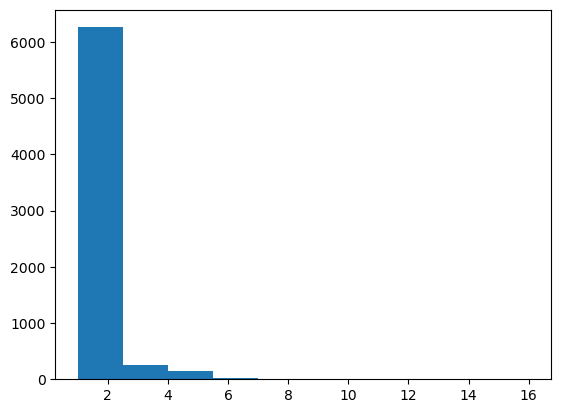

In [145]:
# klastrujemy obserwacje w obszary obserwacji, po współrzędnych geograficznych
# dbscan

from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.05/6371.0, min_samples=1,  metric='haversine') # metryka do danych geograficznych
# min_samples = 1, nie chcemy odrzucać samotnych punktów
clusters = dbscan.fit_predict(np.radians(species_all[["decimalLatitude", "decimalLongitude"]]))
tags, counts = np.unique(clusters, return_counts=True)
plt.hist(counts)

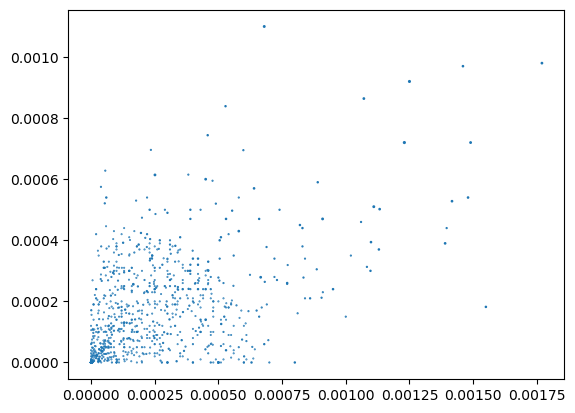

In [ ]:
species_all["cluster"] = clusters
cluster_pd = pd.DataFrame({"cluster": tags, "count": counts})

# sprawdźmy "objętość" klastrów, tzn. min i max współrzędnych geograficznych w każdym klastrze
cluster_pd["min_lat"] = cluster_pd["cluster"].apply(lambda x: species_all[species_all["cluster"] == x]["decimalLatitude"].min())
cluster_pd["max_lat"] = cluster_pd["cluster"].apply(lambda x: species_all[species_all["cluster"] == x]["decimalLatitude"].max())
cluster_pd["min_lon"] = cluster_pd["cluster"].apply(lambda x: species_all[species_all["cluster"] == x]["decimalLongitude"].min())
cluster_pd["max_lon"] = cluster_pd["cluster"].apply(lambda x: species_all[species_all["cluster"] == x]["decimalLongitude"].max())
cluster_pd["lat_span"] = cluster_pd["max_lat"] - cluster_pd["min_lat"]
cluster_pd["lon_span"] = cluster_pd["max_lon"] - cluster_pd["min_lon"]
cluster_pd.head()
plt.scatter(cluster_pd["lon_span"], cluster_pd["lat_span"], s = 0.1*cluster_pd["count"])

In [101]:
# do cluster_pd dodajemy kolumny dla każdego gatunku, z informacją o tym czy występuje w danym klastrze
for species in species_all["species"].unique():
	cluster_pd[species] = cluster_pd["cluster"].apply(lambda x: int(species in species_all[species_all["cluster"] == x]["species"].unique()))

cluster_pd.head()

,cluster,count,min_lat,max_lat,min_lon,max_lon,lat_span,lon_span,Arctostaphylos alpinus,Armeria alpina,...,Linaria alpina,Kalmia procumbens,Petrocallis pyrenaica,Sibbaldia procumbens,Thalictrum alpinum,Woodsia alpina,Astragalus norvegicus,Carex atrofusca,Juncus castaneus,Carex simpliciuscula
0,-1,338,44.111703,47.994009,5.455080,16.164456,3.882306,10.709376,1,1,...,1,1,1,1,1,0,0,0,0,0
1,0,690,45.535000,46.064678,6.238599,7.028863,0.529678,0.790264,1,1,...,1,1,0,1,0,1,0,0,0,0
2,1,197,46.170003,46.686792,7.056183,8.167848,0.516789,1.111665,1,0,...,1,1,0,1,0,0,0,0,0,0
3,2,3862,45.084371,45.695970,6.277900,7.562554,0.611599,1.284654,0,1,...,1,0,1,1,0,1,0,0,0,0
4,3,13,44.616280,44.663296,5.878480,5.934653,0.047016,0.056173,0,1,...,1,0,1,0,0,0,0,0,0,0


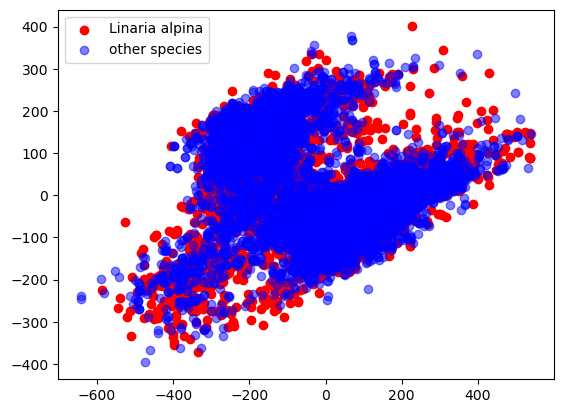

In [134]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(species_all.drop(columns=["decimalLatitude", "decimalLongitude", "cluster", "gbifID", "species", "Cluster", "true_present"]))
# colour only the species Linaria alpina

species_mask = species_all["species"] == "Linaria alpina"
plt.scatter(pca_result[species_mask,0], pca_result[species_mask,1], color="red", label="Linaria alpina")
plt.scatter(pca_result[~species_mask,0], pca_result[~species_mask,1], color="blue", label="other species", alpha=0.5)
plt.legend()

In [115]:
species_all

,gbifID,decimalLongitude,decimalLatitude,wc2.1_30s_bio_10,wc2.1_30s_bio_15,wc2.1_30s_bio_18,wc2.1_30s_bio_19,wc2.1_30s_bio_6,wc2.1_30s_bio_9,Aspect,...,Soil_Organic_Carbon,Soil_pH,Soil_Sand,Topo_Solar_Radiation_MJ,TRI,TWI,true_present,species,Cluster,cluster
0,5760495598,6.677470,46.000181,11.983334,14.858208,327,445,-6.6,11.966666,330.0,...,1212.0,55.0,366.0,0.736255,5.625,7.366544,1,Arctostaphylos alpinus,West,0
1,5760282497,6.677742,46.000385,11.983334,14.858208,327,445,-6.6,11.966666,315.0,...,1212.0,55.0,366.0,0.810410,4.875,7.194194,1,Arctostaphylos alpinus,West,0
2,5109362163,7.417069,46.336584,10.066667,11.673246,292,365,-7.2,10.066667,57.0,...,1554.0,54.0,351.0,0.604245,0.500,8.099392,1,Arctostaphylos alpinus,West,1
3,5005754192,7.800000,46.209102,10.866667,10.429803,241,229,-7.1,10.800000,15.0,...,1510.0,55.0,407.0,0.605776,3.875,8.085495,1,Arctostaphylos alpinus,West,-1
4,4936259716,6.840809,45.764864,8.650001,17.921549,352,539,-9.4,8.650001,324.0,...,957.0,58.0,436.0,0.795682,3.375,9.448774,1,Arctostaphylos alpinus,West,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12160,3011914152,12.516111,47.337222,11.200000,34.110695,491,215,-7.6,-3.716667,76.0,...,1020.0,53.0,307.0,0.674277,1.625,8.952044,1,Woodsia alpina,East,93
12161,3011691658,13.752580,47.213530,11.550000,32.637154,527,228,-9.0,-4.200000,82.0,...,1360.0,54.0,297.0,0.603697,0.625,7.881072,1,Woodsia alpina,East,65
12162,3011275084,11.790277,47.030833,9.916667,36.618053,428,164,-8.6,-5.200000,231.0,...,933.0,56.0,395.0,0.967712,8.500,7.743105,1,Woodsia alpina,East,80
12163,3011264143,12.902170,46.945110,14.200000,41.233578,421,145,-8.1,-1.350000,264.0,...,1095.0,53.0,362.0,0.881311,1.375,7.454949,1,Woodsia alpina,East,65
